# Figure 5 - Analysis/Figure Code

In [ ]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

Median correlations:
Correlation at 10% sampling: 0.4217
Correlation at 20% sampling: 0.7082
Correlation at 30% sampling: 0.7330
Correlation at 40% sampling: 0.8505
Correlation at 50% sampling: 0.8662
Correlation at 60% sampling: 0.9057
Correlation at 70% sampling: 0.9388
Correlation at 80% sampling: 0.9758
Correlation at 90% sampling: 0.9914
Correlation at 100% sampling: 1.0000


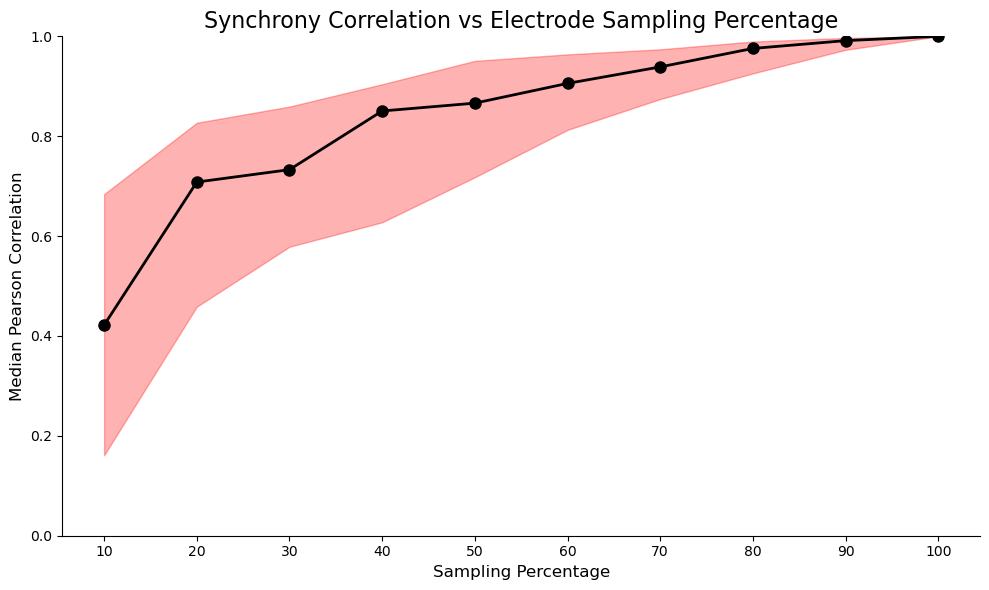

Plot saved as 'median_correlation_with_IQR_plot.png'


In [ ]:
def parse_correlation_string(s):
    try:
        correlations = ast.literal_eval(s)
        return [np.nan if x == 'nan' else float(x) for x in correlations]
    except:
        return [np.nan] * 10

# Read the CSV file
results_df = pd.read_csv('patient_correlations.csv')

# Parse the 'correlations' column
parsed_correlations = results_df['correlations'].apply(parse_correlation_string)

# Create a new DataFrame with parsed correlations
correlation_df = pd.DataFrame(parsed_correlations.tolist(), columns=[f'corr_{i*10}%' for i in range(1, 11)])

# Calculate median and quartiles
median_correlations = correlation_df.median()
q1_correlations = correlation_df.quantile(0.25)
q3_correlations = correlation_df.quantile(0.75)

# Print median correlations
print("Median correlations:")
for i, corr in enumerate(median_correlations):
    print(f"Correlation at {(i+1)*10}% sampling: {corr:.4f}")

# Plot the results using Matplotlib
plt.figure(figsize=(10, 6))

# Plot median line
plt.plot(range(10, 101, 10), median_correlations, marker='o', linestyle='-', linewidth=2, markersize=8, color='k')

# Fill IQR
plt.fill_between(range(10, 101, 10), q1_correlations, q3_correlations, alpha=0.3, color='red')

plt.title('Synchrony Correlation vs Electrode Sampling Percentage', fontsize=16)
plt.xlabel('Sampling Percentage', fontsize=12)
plt.ylabel('Median Pearson Correlation', fontsize=12)
plt.xticks(range(10, 101, 10))
plt.ylim(0, 1)  # Assuming correlations are between 0 and 1
# plt.legend()
plt.tight_layout()
# plt.grid(True, linestyle='--', alpha=0.7)
sns.despine()

# plt.savefig('median_correlation_with_IQR_plot.png', dpi=300)
plt.show()